# Prática 2 — Construindo um rating Elo do zero

**Objetivo:** dar a cada time uma "nota de força" que se atualiza jogo a jogo. Essa nota vai ser a **primeira feature** do nosso modelo.

**A ideia do Elo** (criado para o xadrez, hoje usado em quase todo esporte):
1. Cada time tem uma nota. Todos começam com 1500.
2. Antes do jogo, a diferença de notas diz o resultado **esperado**.
3. Depois do jogo, comparamos o esperado com o que **aconteceu** e ajustamos as notas na proporção da surpresa.

Repare no passo 3: o modelo **aprende com o próprio erro**. Essa é a ideia central de praticamente todo o machine learning. O Elo é a versão mais simples dela.

**Como usar:** igual à prática 1. Complete os `___`, use as dicas e deixe o gabarito para o fim.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

candidatos = [Path("data/processed/partidas.csv"), Path("../data/processed/partidas.csv")]
CAMINHO = next((c for c in candidatos if c.exists()), None)
if CAMINHO is None:
    raise FileNotFoundError("Não achei o arquivo. Rode antes no terminal: python 01_coleta_dados.py")

partidas = pd.read_csv(CAMINHO, parse_dates=["data"])
# O Elo depende da ORDEM dos jogos, então garantimos a ordem cronológica.
partidas = partidas.sort_values(["temporada", "data"]).reset_index(drop=True)
print("Linhas e colunas:", partidas.shape)

Linhas e colunas: (5628, 18)


## Passo 1 — O resultado esperado

A fórmula do Elo transforma a diferença de notas em um número entre 0 e 1:

$$\text{esperado} = \frac{1}{1 + 10^{-\text{diferença}/400}}$$

em que **diferença = (nota do mandante + vantagem de casa) − nota do visitante**.

Como ler o resultado: 1 = vitória certa do mandante, 0 = derrota certa, 0,5 = equilíbrio. Ele funciona como os "pontos esperados" do mandante numa escala em que vitória vale 1, empate 0,5 e derrota 0.

A **vantagem de casa** é um bônus de pontos de Elo que o mandante ganha só por jogar em casa.

**Exercício 1:** complete a fórmula.

> Dica: a variável que vai no lugar do `___` foi calculada na linha de cima.

In [3]:
def resultado_esperado(rating_mandante, rating_visitante, vantagem_casa):
    diferenca = (rating_mandante + vantagem_casa) - rating_visitante
    return 1 / (1 + 10 ** (-diferenca / 400))

# Testes: confira se os números fazem sentido
print(resultado_esperado(1500, 1500, 0))    # times iguais, campo neutro
print(resultado_esperado(1500, 1500, 80))   # times iguais, com vantagem de casa
print(resultado_esperado(1600, 1400, 80))   # time forte em casa contra time fraco

0.5
0.6131368201531431
0.8336624691834381


✍️ **Para conferir:** o primeiro teste deve dar exatamente 0,5. O terceiro deve dar cerca de 0,83.

## Passo 2 — Aprender com o erro

Depois do jogo, a nota muda assim:

$$\text{ajuste} = K \times (\text{real} - \text{esperado})$$

- **real** é 1 (vitória do mandante), 0,5 (empate) ou 0 (vitória do visitante).
- **K** controla a velocidade de aprendizado. K alto faz as notas reagirem muito a cada jogo; K baixo faz elas mudarem devagar.
- O mandante **ganha** o ajuste e o visitante **perde** o mesmo valor. O total de pontos não muda.

**Exercício 2:** complete a conta do ajuste.

> Dica: é a diferença entre o que aconteceu e o que se esperava. As duas variáveis já existem na função.

In [4]:
PONTOS_REAIS = {"M": 1.0, "E": 0.5, "V": 0.0}

def atualizar(rating_mandante, rating_visitante, resultado, vantagem_casa, K):
    esperado = resultado_esperado(rating_mandante, rating_visitante, vantagem_casa)
    real = PONTOS_REAIS[resultado]
    ajuste = K * (real - esperado)
    return rating_mandante + ajuste, rating_visitante - ajuste

# Zebra: time de 1400 vence FORA um time de 1600
print(atualizar(1600, 1400, "V", vantagem_casa=80, K=20))
# Favorito faz o esperado: time de 1600 vence EM CASA um time de 1400
print(atualizar(1600, 1400, "M", vantagem_casa=80, K=20))

(1583.3267506163313, 1416.6732493836687)
(1603.3267506163313, 1396.6732493836687)


✍️ **Para pensar:** na zebra, o time mais fraco ganha uns 17 pontos. Quando o favorito vence, ele ganha só uns 3. Por que essa diferença faz sentido?

## Passo 3 — Rodar a história inteira (2012 → 2026)

Agora aplicamos as duas funções a todos os jogos, em ordem. Há três detalhes importantes, todos comentados no código:

**a) Guardar a nota ANTES do jogo.** Quando o modelo for prever um jogo, ele só pode usar o que se sabia antes de a bola rolar. Se usássemos a nota de depois do jogo, o resultado já estaria "embutido" nela, e o modelo pareceria ótimo nos testes e fracassaria na vida real. Esse erro tem nome: **vazamento de dados** (*data leakage*). É um dos erros mais comuns em machine learning.

**b) Regressão à média entre temporadas.** Os times mudam muito de um ano para o outro: elenco, técnico, dinheiro. Por isso, no início de cada temporada, aproximamos todas as notas de 1500. Com `regressao = 0.3`, cada time perde 30% da distância até a média.

**c) Times promovidos.** Quem acabou de subir da Série B não tem nota recente na Série A. Começa com uma nota abaixo da média (1450), porque times promovidos costumam ser mais fracos.

**Exercício 3:** complete a regressão à média.

> Dica: com `regressao = 0.3`, um time com nota 1600 deve começar a temporada seguinte com 1570. Ele está 100 acima da média e mantém 70% dessa distância.

In [15]:
def calcular_elo(partidas, K=40, vantagem_casa=80, regressao=0.3, rating_promovido=1450):
    """Percorre todos os jogos em ordem e devolve:
    - a tabela de partidas com as notas de antes de cada jogo;
    - um dicionário com a nota atual de cada time."""
    ratings = {}                 # nota atual de cada time
    times_temporada_anterior = set()
    pre_mandante, pre_visitante, esperados = [], [], []
    primeira_temporada = partidas["temporada"].min()

    for temporada, jogos in partidas.groupby("temporada", sort=True):
        # --- Início da temporada: ajusta as notas (detalhes b e c) ---
        times = set(jogos["mandante"]) | set(jogos["visitante"])
        for time in times:
            if temporada == primeira_temporada:
                ratings[time] = 1500                         # ninguém tem histórico ainda
            elif time in times_temporada_anterior:
                ratings[time] = 1500 + (ratings[time] - 1500) * (1 -regressao)  # ajusta a nota do time que já estava na temporada anterior
            else:
                ratings[time] = rating_promovido             # acabou de subir
        times_temporada_anterior = times

        # --- Jogo a jogo ---
        for mandante, visitante, resultado in zip(jogos["mandante"], jogos["visitante"], jogos["resultado"]):
            # (a) guarda as notas ANTES de atualizar
            pre_mandante.append(ratings[mandante])
            pre_visitante.append(ratings[visitante])
            esperados.append(resultado_esperado(ratings[mandante], ratings[visitante], vantagem_casa))
            # só agora aprende com o resultado
            ratings[mandante], ratings[visitante] = atualizar(
                ratings[mandante], ratings[visitante], resultado, vantagem_casa, K)

    saida = partidas.copy()
    saida["elo_pre_mandante"] = pre_mandante
    saida["elo_pre_visitante"] = pre_visitante
    saida["esperado"] = esperados
    saida["real"] = saida["resultado"].map(PONTOS_REAIS)
    return saida, ratings

com_elo, ratings_atuais = calcular_elo(partidas)
com_elo[["temporada", "mandante", "visitante", "elo_pre_mandante", "elo_pre_visitante", "esperado", "resultado"]].tail(5)

,temporada,mandante,visitante,elo_pre_mandante,elo_pre_visitante,esperado,resultado
5623,2026,Fluminense,Santos,1603.870137,1559.678137,0.671484,V
5624,2026,Grêmio,Cruzeiro,1422.965882,1592.581134,0.373819,V
5625,2026,Remo,Bragantino,1395.259244,1495.821453,0.470443,E
5626,2026,São Paulo,Vasco,1468.291803,1490.636849,0.582219,M
5627,2026,Corinthians,Vitória,1416.249627,1457.445077,0.555613,E


✍️ **Para pensar:** se um time sobe da Série B, cai no mesmo ano e volta dois anos depois, com que nota ele recomeça? Isso é bom ou ruim?

## Passo 4 — O ranking de 2026 segundo o Elo

`ratings_atuais` é um **dicionário** (`{"Flamengo": 1657.7, ...}`). Para trabalhar com ele no pandas, transformamos em uma tabela. Depois, ficamos só com os times que disputam 2026, porque o dicionário também tem os clubes que já caíram.

**Exercício 4:** ordene do **menor** Elo para o maior, para ver quem está mais ameaçado.

> Dica: é o mesmo método do Passo 5 da prática 1. Ele recebe o nome da coluna pela qual ordenar.

In [8]:
times_2026 = set(partidas.loc[partidas["temporada"] == 2026, "mandante"])

ranking = pd.DataFrame(list(ratings_atuais.items()), columns=["time", "elo"])
ranking = ranking[ranking["time"].isin(times_2026)]
ranking = ranking.sort_values("elo", ascending=False).reset_index(drop=True)
ranking["elo"] = ranking["elo"].round(0)
ranking.head(8)

,time,elo
0,Flamengo,1660.0
1,Palmeiras,1645.0
2,Cruzeiro,1572.0
3,Fluminense,1559.0
4,Atlético-MG,1542.0
5,Bahia,1535.0
6,Athletico-PR,1532.0
7,Santos,1530.0


✍️ **Para comparar:** na tabela real, depois dos jogos até 20/10, o Z4 era Chapecoense (18 pts), Remo (26), Grêmio (31) e Internacional (32). Logo acima vinham Corinthians (33) e Vasco (35).

O Elo concorda com a tabela? Algum time está bem mais alto ou mais baixo no Elo do que na classificação? O que pode explicar isso?

## Passo 5 — O Elo acerta?

Um modelo que diz "70% de chance" precisa acertar mais ou menos 70% das vezes. Quando isso acontece, dizemos que ele é **bem calibrado**.

Para checar, separamos os jogos em faixas de `esperado` (0,3–0,4, 0,4–0,5 etc.) e calculamos, em cada faixa, a média do que **realmente** aconteceu. Se o Elo estiver bem calibrado, as duas colunas devem ficar parecidas.

`pd.cut` cria as faixas. Para não misturar os anos "de aquecimento", quando as notas ainda estão se ajustando, usamos só de 2015 em diante.

**Exercício 5:** agrupe pela coluna de faixas.

> Dica: o nome da coluna nova foi criado na primeira linha depois do filtro.

In [10]:
avaliacao = com_elo[com_elo["temporada"] >= 2015].copy()
avaliacao["faixa"] = pd.cut(avaliacao["esperado"], bins=[0, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1])

calibracao = avaliacao.groupby("faixa", observed=True).agg(
    jogos=("real", "size"),
    esperado_medio=("esperado", "mean"),
    real_medio=("real", "mean"),
)
calibracao.round(3)

,jogos,esperado_medio,real_medio
faixa,,,
"(0.0, 0.3]",8,0.275,0.250
"(0.3, 0.4]",105,0.367,0.381
"(0.4, 0.5]",591,0.461,0.477
"(0.5, 0.6]",1332,0.555,0.555
"(0.6, 0.7]",1565,0.649,0.654
"(0.7, 0.8]",801,0.739,0.761
"(0.8, 1.0]",86,0.825,0.831


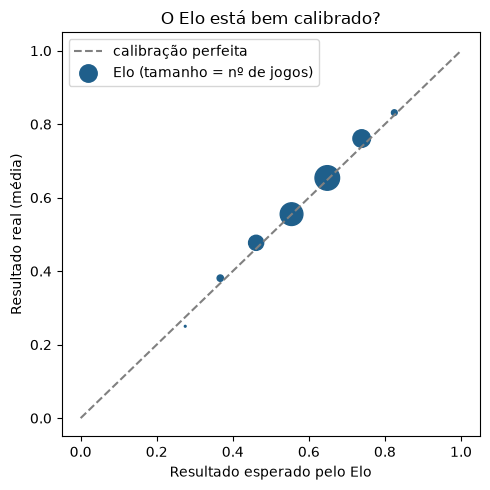

In [11]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="calibração perfeita")
ax.scatter(calibracao["esperado_medio"], calibracao["real_medio"],
           s=calibracao["jogos"] / 5, color="#1f5f8b", label="Elo (tamanho = nº de jogos)")
ax.set_xlabel("Resultado esperado pelo Elo")
ax.set_ylabel("Resultado real (média)")
ax.set_title("O Elo está bem calibrado?")
ax.legend()
plt.tight_layout()
plt.show()

### Uma nota para o modelo: o erro quadrático médio

Para comparar versões do Elo, precisamos de **um número só** que resuma o erro. Vamos usar o **erro quadrático médio** (EQM): para cada jogo, calculamos `(real − esperado)²` e tiramos a média. Quanto **menor**, melhor.

Para saber se o número é bom, comparamos com um modelo "preguiçoso", que ignora os times e chuta sempre a mesma coisa: a média histórica (cerca de 0,61, porque o mandante leva vantagem).

In [12]:
def erro_quadratico_medio(tabela):
    return ((tabela["real"] - tabela["esperado"]) ** 2).mean()

eqm_elo = erro_quadratico_medio(avaliacao)
eqm_preguicoso = ((avaliacao["real"] - avaliacao["real"].mean()) ** 2).mean()

print(f"EQM do Elo:             {eqm_elo:.4f}")
print(f"EQM do chute constante: {eqm_preguicoso:.4f}")
print(f"Melhora: {1 - eqm_elo / eqm_preguicoso:.1%}")

EQM do Elo:             0.1584
EQM do chute constante: 0.1690
Melhora: 6.3%


✍️ **Para pensar:** a melhora parece pequena. Isso é normal no futebol, um esporte com poucos gols e muito acaso. Mesmo as casas de apostas erram muito jogo a jogo. O que importa é que, somadas em milhares de simulações, pequenas vantagens viram probabilidades de rebaixamento bem diferentes.

## Desafio — Seu primeiro ajuste de hiperparâmetro

`K`, `vantagem_casa`, `regressao` e `rating_promovido` são **hiperparâmetros**: valores que o modelo não aprende sozinho, nós é que escolhemos. Um jeito de escolher é testar vários e ficar com o que erra menos.

Na prática 1, vimos que o fator casa diminuiu ao longo dos anos. Vamos ver se o Elo concorda: teste vários valores de `vantagem_casa` e meça o erro **separadamente** em 2013–2016 e em 2021–2025.

**Exercício extra:** complete o filtro do segundo período.

> Dica: `between(a, b)` inclui os dois extremos. Copie o padrão da linha de cima.

In [ ]:
resultados = []
for vc in [40, 60, 80, 100, 120]:
    tabela, _ = calcular_elo(partidas, vantagem_casa=vc)
    antigo = tabela[tabela["temporada"].between(2013, 2016)]
    recente = tabela[tabela["temporada"].between(2021, 2025)]
    resultados.append({
        "vantagem_casa": vc,
        "eqm_2013_2016": erro_quadratico_medio(antigo),
        "eqm_2021_2025": erro_quadratico_medio(recente),
    })

pd.DataFrame(resultados).round(5)

,vantagem_casa,eqm_2013_2016,eqm_2021_2025
0,40,0.16750,0.16156
1,60,0.16325,0.15940
2,80,0.16060,0.15877
3,100,0.15946,0.15959
4,120,0.15972,0.16171


✍️ **Responda:**
1. Qual `vantagem_casa` dá o menor erro em cada período?
2. Isso confirma ou contradiz o que você viu na prática 1?
3. Se quiser, teste também `K` com os valores 10, 20, 30 e 40. Basta trocar o parâmetro no loop. Qual funciona melhor?

⚠️ **Um cuidado para o futuro:** estamos escolhendo o hiperparâmetro e medindo o erro **nos mesmos dados**. Isso tende a deixar o resultado otimista demais. Na etapa de backtest, vamos separar os dados de escolha dos dados de avaliação. Por enquanto, para entender o conceito, está ótimo.

---

### Me conte o que você encontrou
Mande suas respostas do Passo 4 e do desafio. Com elas, fechamos os hiperparâmetros do Elo e levamos tudo para o script `02_features.py`.

---
# Gabarito

**1.** `return 1 / (1 + 10 ** (-diferenca / 400))`

**2.** `ajuste = K * (real - esperado)`

**3.** `ratings[time] = 1500 + (ratings[time] - 1500) * (1 - regressao)`

**4.** `ranking = ranking.sort_values("elo").reset_index(drop=True)`

**5.** `calibracao = avaliacao.groupby("faixa", observed=True).agg(...)`

**Extra.** `recente = tabela[tabela["temporada"].between(2021, 2025)]`

**Erros comuns**
- `NameError: name 'regressao' is not defined` → confira a grafia. O nome é o mesmo do parâmetro da função, sem acento.
- Ratings estranhos, como todos 1500 ou números enormes → você rodou o Passo 3 antes de corrigir os Passos 1 e 2? Rode as células de novo, na ordem.
- `ajuste = K * (esperado - real)` → com a ordem invertida, quem vence **perde** pontos! O sinal importa.